In [1]:
import sys
REPO = r"C:\Users\saqib\OneDrive\Desktop\Sem 5\AI\Project\telecom-value-based-retention"
sys.path.append(REPO)

In [2]:
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from src.utils.config import SEED, PROCESSED_DATA_DIR

# Loading Data

In [3]:

sys.path.append("..")

train = pd.read_csv(PROCESSED_DATA_DIR / "train_encoded.csv")
val   = pd.read_csv(PROCESSED_DATA_DIR / "val_encoded.csv")
test  = pd.read_csv(PROCESSED_DATA_DIR / "test_encoded.csv")
print(train.shape, val.shape, test.shape)

(4930, 85) (1056, 85) (1057, 85)


# Prep X and Y

In [4]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 85 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 4930 non-null   float64
 1   Number of Dependents                4930 non-null   float64
 2   Latitude                            4930 non-null   float64
 3   Longitude                           4930 non-null   float64
 4   Number of Referrals                 4930 non-null   float64
 5   Tenure in Months                    4930 non-null   float64
 6   Avg Monthly Long Distance Charges   4930 non-null   float64
 7   Avg Monthly GB Download             4930 non-null   float64
 8   Monthly Charge                      4930 non-null   float64
 9   Total Charges                       4930 non-null   float64
 10  Total Refunds                       4930 non-null   float64
 11  Total Extra Data Charges            4930 no

In [5]:
X_train = train.drop(columns = ['Churn','City','Zip Code'])

In [6]:
y_train = train["Churn"]

In [7]:
X_val = val.drop(columns = ['Churn','City','Zip Code'])
y_val = val["Churn"]

In [8]:
X_test = test.drop(columns=["Churn", "City", "Zip Code"])
y_test = test["Churn"]

In [9]:
print("X shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Churn rate:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print(f"churners: {pos}, non-churners: {neg}, scale_pos_weight: {spw:.2f}")

X shapes: (4930, 82) (1056, 82) (1057, 82)
Churn rate: 0.265 0.265 0.266
churners: 1308, non-churners: 3622, scale_pos_weight: 2.77


In [10]:
def clean_names(df):
    return df.rename(columns=lambda c: c.replace("<", "lt_").replace("[", "(").replace("]", ")"))

X_train, X_val, X_test = clean_names(X_train), clean_names(X_val), clean_names(X_test)
print([c for c in X_train.columns if "Age_Band" in c])

['Age_Band_30-50', 'Age_Band_50+', 'Age_Band_lt_30']


# Models

## Logistic Regression

In [11]:
print(SEED)

42


In [12]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

In [13]:
from tqdm.auto import tqdm

with tqdm(total=1, desc="Training Logistic Regression") as bar:
    lr.fit(X_train, y_train)
    bar.update(1)

Training Logistic Regression:   0%|          | 0/1 [00:00<?, ?it/s]

In [14]:
val_proba = lr.predict_proba(X_val)[:, 1]
print(val_proba[:10].round(3))

[0.013 0.699 0.002 0.061 0.948 0.936 0.023 0.709 0.558 0.015]


In [15]:
threshold = 0.5
val_pred = (val_proba >= threshold).astype(int)
print("Predicted churners:", val_pred.sum(), "out of", len(val_pred))
print("Actual churners:   ", y_val.sum(),"out of", len(y_val))

Predicted churners: 405 out of 1056
Actual churners:    280 out of 1056


In [16]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

print("ROC-AUC  :", round(roc_auc_score(y_val, val_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, val_proba), 3))
print("Precision:", round(precision_score(y_val, val_pred), 3))
print("Recall   :", round(recall_score(y_val, val_pred), 3))
print("F1       :", round(f1_score(y_val, val_pred), 3))

ROC-AUC  : 0.886
PR-AUC   : 0.736
Precision: 0.568
Recall   : 0.821
F1       : 0.672


In [17]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_val, val_pred))

[[601 175]
 [ 50 230]]


## Random Forest

In [18]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=SEED
)

In [19]:
rf.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', min_samples_leaf=5,
                       n_estimators=300, random_state=42)

In [20]:
rf_proba = rf.predict_proba(X_val)[:, 1]
print(rf_proba[:10].round(3))

[0.052 0.567 0.008 0.11  0.84  0.74  0.014 0.434 0.382 0.16 ]


In [21]:
threshold = 0.5
rf_pred = (rf_proba >= threshold).astype(int)
print("Predicted churners:", rf_pred.sum(), "out of", len(rf_pred))
print("Actual churners:   ", y_val.sum())

Predicted churners: 331 out of 1056
Actual churners:    280


In [22]:
print("ROC-AUC  :", round(roc_auc_score(y_val, rf_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, rf_proba), 3))
print("Precision:", round(precision_score(y_val, rf_pred), 3))
print("Recall   :", round(recall_score(y_val, rf_pred), 3))
print("F1       :", round(f1_score(y_val, rf_pred), 3))

ROC-AUC  : 0.895
PR-AUC   : 0.753
Precision: 0.634
Recall   : 0.75
F1       : 0.687


In [23]:
print(confusion_matrix(y_val, rf_pred))

[[655 121]
 [ 70 210]]


## XG Boost

In [24]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [25]:
from xgboost import XGBClassifier
from tqdm.auto import tqdm
from xgboost.callback import TrainingCallback

class TqdmProgress(TrainingCallback):
    def __init__(self, total):
        self.bar = tqdm(total=total, desc="Training XGBoost")
    def after_iteration(self, model, epoch, evals_log):
        self.bar.update(1)
        return False          # False means "keep training"
    def after_training(self, model):
        self.bar.close()
        return model

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=SEED,
    callbacks=[TqdmProgress(300)]
)
xgb.fit(X_train, y_train)

Training XGBoost:   0%|          | 0/300 [00:00<?, ?it/s]

XGBClassifier(base_score=None, booster=None,
              callbacks=[<__main__.TqdmProgress object at 0x000002D0B10E3CB0>],
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [26]:
xgb_proba = xgb.predict_proba(X_val)[:, 1]
print(xgb_proba[:10].round(3))

[0.019 0.882 0.003 0.01  0.88  0.959 0.012 0.739 0.314 0.063]


In [27]:
threshold = 0.5
xgb_pred = (xgb_proba >= threshold).astype(int)
print("Predicted churners:", xgb_pred.sum(), "out of", len(xgb_pred))
print("Actual churners:   ", y_val.sum())

Predicted churners: 372 out of 1056
Actual churners:    280


In [28]:
print("ROC-AUC  :", round(roc_auc_score(y_val, xgb_proba), 3))
print("PR-AUC   :", round(average_precision_score(y_val, xgb_proba), 3))
print("Precision:", round(precision_score(y_val, xgb_pred), 3))
print("Recall   :", round(recall_score(y_val, xgb_pred), 3))
print("F1       :", round(f1_score(y_val, xgb_pred), 3))

ROC-AUC  : 0.898
PR-AUC   : 0.769
Precision: 0.602
Recall   : 0.8
F1       : 0.687


In [29]:
print(confusion_matrix(y_val, xgb_pred))

[[628 148]
 [ 56 224]]


# Model Comparison

In [30]:
lr_proba, lr_pred = val_proba, val_pred

In [31]:
probas = {"Logistic Regression": lr_proba, "Random Forest": rf_proba, "XGBoost": xgb_proba}
preds  = {"Logistic Regression": lr_pred,  "Random Forest": rf_pred,  "XGBoost": xgb_pred}

rows = []
for name in probas:
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val, probas[name]),
        "PR-AUC": average_precision_score(y_val, probas[name]),
        "Precision": precision_score(y_val, preds[name]),
        "Recall": recall_score(y_val, preds[name]),
        "F1": f1_score(y_val, preds[name]),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,ROC-AUC,PR-AUC,Precision,Recall,F1
Model,,,,,
Logistic Regression,0.886,0.736,0.568,0.821,0.672
Random Forest,0.895,0.753,0.634,0.750,0.687
XGBoost,0.898,0.769,0.602,0.800,0.687


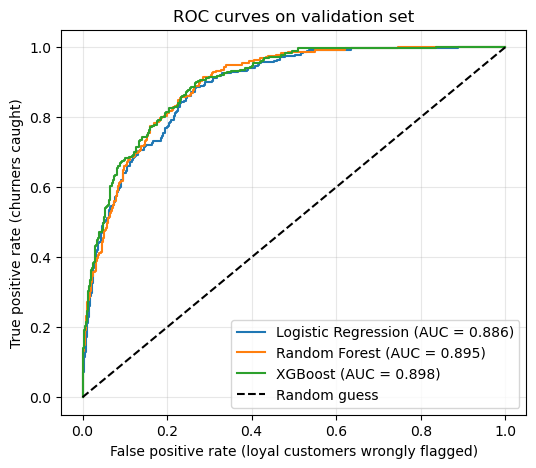

In [32]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_val, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate (loyal customers wrongly flagged)")
plt.ylabel("True positive rate (churners caught)")
plt.title("ROC curves on validation set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

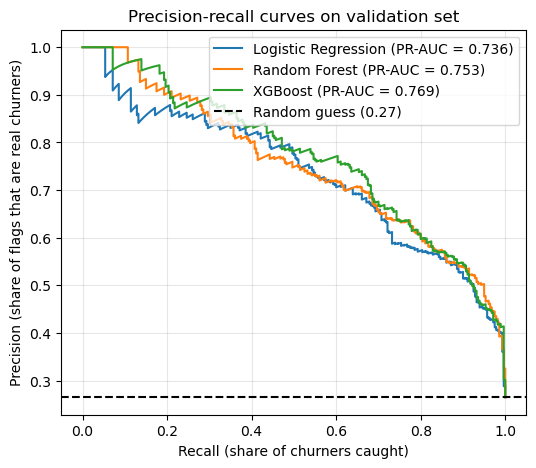

In [33]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(6, 5))
for name, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_val, p)
    plt.plot(rec, prec, label=f"{name} (PR-AUC = {average_precision_score(y_val, p):.3f})")
plt.axhline(y_val.mean(), color="k", linestyle="--", label=f"Random guess ({y_val.mean():.2f})")
plt.xlabel("Recall (share of churners caught)")
plt.ylabel("Precision (share of flags that are real churners)")
plt.title("Precision-recall curves on validation set")
plt.legend(loc = "upper right")
plt.grid(alpha=0.3)
plt.show()

# Final Testing on test dataset

In [34]:
xgb_test_proba = xgb.predict_proba(X_test)[:, 1]
print(xgb_test_proba[:10].round(3))

[0.876 0.022 0.569 0.162 0.008 0.124 0.787 0.27  0.027 0.94 ]


In [35]:
threshold = 0.5
xgb_test_pred = (xgb_test_proba >= threshold).astype(int)
print("Predicted churners:", xgb_test_pred.sum(), "out of", len(xgb_test_pred))
print("Actual churners:   ", y_test.sum())

Predicted churners: 389 out of 1057
Actual churners:    281


In [36]:
threshold = 0.5
xgb_test_pred = (xgb_test_proba >= threshold).astype(int)
print("Predicted churners:", xgb_test_pred.sum(), "out of", len(xgb_test_pred))
print("Actual churners:   ", y_test.sum())

Predicted churners: 389 out of 1057
Actual churners:    281


In [37]:
print(confusion_matrix(y_test, xgb_test_pred))

[[622 154]
 [ 46 235]]


In [38]:
compare = pd.DataFrame({
    "Validation": [roc_auc_score(y_val, xgb_proba), average_precision_score(y_val, xgb_proba),
                   precision_score(y_val, xgb_pred), recall_score(y_val, xgb_pred), f1_score(y_val, xgb_pred)],
    "Test":       [roc_auc_score(y_test, xgb_test_proba), average_precision_score(y_test, xgb_test_proba),
                   precision_score(y_test, xgb_test_pred), recall_score(y_test, xgb_test_pred), f1_score(y_test, xgb_test_pred)],
}, index=["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]).round(3)
compare

,Validation,Test
ROC-AUC,0.898,0.908
PR-AUC,0.769,0.788
Precision,0.602,0.604
Recall,0.800,0.836
F1,0.687,0.701


In [39]:
from sklearn.metrics import accuracy_score

print("Validation accuracy:", round(accuracy_score(y_val, xgb_pred), 3))
print("Test accuracy:      ", round(accuracy_score(y_test, xgb_test_pred), 3))

Validation accuracy: 0.807
Test accuracy:       0.811


# Feature Importance

In [40]:
gain = xgb.get_booster().get_score(importance_type="gain")
importance = pd.Series(gain).sort_values(ascending=False)
importance = importance / importance.sum()

print("Features used by the model:", len(importance), "of", X_train.shape[1])
importance.head(15).round(4)

Features used by the model: 69 of 82


Contract_Month-to-Month       0.1851
Contract_Two Year             0.0760
Contract_One Year             0.0717
Premium Tech Support_No       0.0420
Online Security_No            0.0418
Number of Referrals           0.0325
Number of Dependents          0.0286
Has_Dependents                0.0272
Married_Yes                   0.0253
Payment Method_Credit Card    0.0209
Internet Type_Fiber Optic     0.0175
Streaming TV_Yes              0.0158
Paperless Billing_Yes         0.0157
Married_No                    0.0146
Streaming Movies_Yes          0.0133
dtype: float64

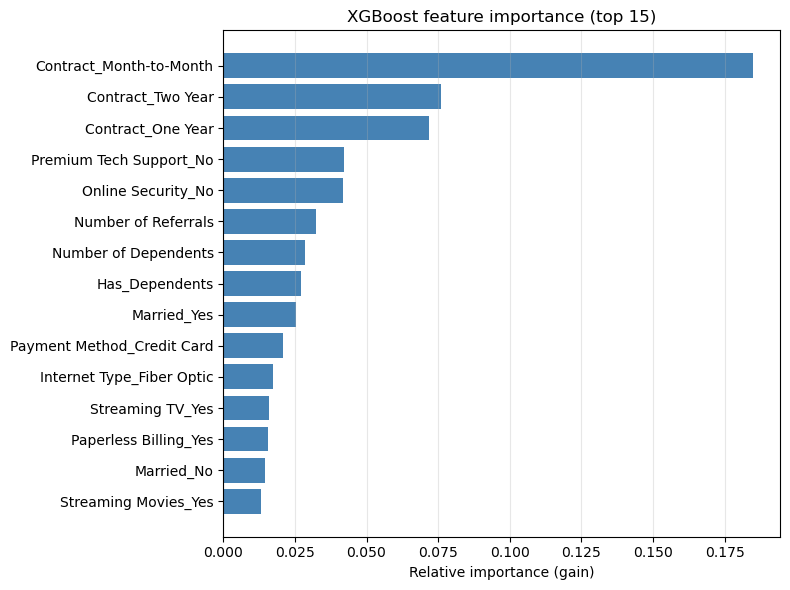

In [41]:
top = importance.head(15).sort_values()       # sorted so the biggest bar ends up on top

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="steelblue")
plt.xlabel("Relative importance (gain)")
plt.title("XGBoost feature importance (top 15)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
parents = ["Gender", "Married", "Offer", "Phone Service", "Multiple Lines", "Internet Service",
           "Internet Type", "Online Security", "Online Backup", "Device Protection Plan",
           "Premium Tech Support", "Streaming TV", "Streaming Movies", "Streaming Music",
           "Unlimited Data", "Contract", "Paperless Billing", "Payment Method",
           "Age_Band", "Tenure_Group"]

def parent_of(col):
    for p in parents:
        if col.startswith(p + "_"):
            return p
    return col                                 # numeric features keep their own name

grouped = importance.groupby(parent_of).sum().sort_values(ascending=False)
grouped.head(12).round(4)

Contract                0.3328
Premium Tech Support    0.0490
Online Security         0.0483
Married                 0.0399
Offer                   0.0381
Payment Method          0.0338
Number of Referrals     0.0325
Internet Type           0.0290
Number of Dependents    0.0286
Paperless Billing       0.0276
Has_Dependents          0.0272
Tenure_Group            0.0233
dtype: float64

# Phase 4: Evaluation and Analysis

## Section 1

In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

dummy = DummyClassifier(strategy="stratified", random_state=SEED)
dummy.fit(X_train, y_train)
d_proba = dummy.predict_proba(X_val)[:, 1]
d_pred = dummy.predict(X_val)

print("Dummy ROC-AUC  :", round(roc_auc_score(y_val, d_proba), 3))
print("Dummy PR-AUC   :", round(average_precision_score(y_val, d_proba), 3))
print("Dummy Precision:", round(precision_score(y_val, d_pred), 3))
print("Dummy Recall   :", round(recall_score(y_val, d_pred), 3))
print("Dummy F1       :", round(f1_score(y_val, d_pred), 3))

Dummy ROC-AUC  : 0.496
Dummy PR-AUC   : 0.264
Dummy Precision: 0.259
Dummy Recall   : 0.257
Dummy F1       : 0.258


In [44]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from tqdm.auto import tqdm

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Precision": "precision",
           "Recall": "recall", "F1": "f1", "Accuracy": "accuracy", "Brier": "neg_brier_score"}

In [45]:
from sklearn.linear_model import LogisticRegression

lr_cv = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)

with tqdm(total=1, desc="Cross-validating Logistic Regression") as bar:
    res_lr = cross_validate(lr_cv, X_train, y_train, cv=cv, scoring=scoring)
    bar.update(1)

summary_lr = pd.DataFrame(res_lr).drop(columns=["fit_time", "score_time"]).agg(["mean", "std"]).T.round(3)
summary_lr

Cross-validating Logistic Regression:   0%|          | 0/1 [00:00<?, ?it/s]

,mean,std
test_ROC-AUC,0.903,0.006
test_PR-AUC,0.777,0.018
test_Precision,0.588,0.001
test_Recall,0.848,0.022
test_F1,0.694,0.007
test_Accuracy,0.802,0.002
test_Brier,-0.131,0.004


In [46]:
from sklearn.ensemble import RandomForestClassifier

rf_cv = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                               class_weight="balanced", n_jobs=-1, random_state=SEED)

with tqdm(total=1, desc="Cross-validating Random Forest") as bar:
    res_rf = cross_validate(rf_cv, X_train, y_train, cv=cv, scoring=scoring)
    bar.update(1)

summary_rf = pd.DataFrame(res_rf).drop(columns=["fit_time", "score_time"]).agg(["mean", "std"]).T.round(3)
summary_rf

Cross-validating Random Forest:   0%|          | 0/1 [00:00<?, ?it/s]

,mean,std
test_ROC-AUC,0.899,0.001
test_PR-AUC,0.771,0.010
test_Precision,0.661,0.009
test_Recall,0.751,0.016
test_F1,0.703,0.010
test_Accuracy,0.832,0.005
test_Brier,-0.117,0.002


In [47]:
from xgboost import XGBClassifier

xgb_cv = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                       colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
                       n_jobs=-1, random_state=SEED)

with tqdm(total=1, desc="Cross-validating XGBoost") as bar:
    res_xgb = cross_validate(xgb_cv, X_train, y_train, cv=cv, scoring=scoring)
    bar.update(1)

summary_xgb = pd.DataFrame(res_xgb).drop(columns=["fit_time", "score_time"]).agg(["mean", "std"]).T.round(3)
summary_xgb

Cross-validating XGBoost:   0%|          | 0/1 [00:00<?, ?it/s]

,mean,std
test_ROC-AUC,0.914,0.005
test_PR-AUC,0.808,0.015
test_Precision,0.655,0.007
test_Recall,0.814,0.029
test_F1,0.726,0.015
test_Accuracy,0.837,0.007
test_Brier,-0.113,0.004


In [48]:
cv_mean = pd.concat({"Logistic Regression": summary_lr["mean"],
                     "Random Forest": summary_rf["mean"],
                     "XGBoost": summary_xgb["mean"]}, axis=1).T
cv_std = pd.concat({"Logistic Regression": summary_lr["std"],
                    "Random Forest": summary_rf["std"],
                    "XGBoost": summary_xgb["std"]}, axis=1).T

cv_mean.columns = cv_mean.columns.str.replace("test_", "")
cv_std.columns = cv_std.columns.str.replace("test_", "")
cv_mean["Brier"] = -cv_mean["Brier"]          # flip the sign back

print("Mean of 5 folds"); display(cv_mean)
print("Standard deviation across folds"); display(cv_std)

Mean of 5 folds


,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier
Logistic Regression,0.903,0.777,0.588,0.848,0.694,0.802,0.131
Random Forest,0.899,0.771,0.661,0.751,0.703,0.832,0.117
XGBoost,0.914,0.808,0.655,0.814,0.726,0.837,0.113


Standard deviation across folds


,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier
Logistic Regression,0.006,0.018,0.001,0.022,0.007,0.002,0.004
Random Forest,0.001,0.010,0.009,0.016,0.010,0.005,0.002
XGBoost,0.005,0.015,0.007,0.029,0.015,0.007,0.004


## Section 2

In [49]:
from sklearn.metrics import brier_score_loss, accuracy_score, confusion_matrix

In [50]:
lr_test_proba = lr.predict_proba(X_test)[:, 1]
lr_test_pred = (lr_test_proba >= 0.5).astype(int)

lr_test = {"ROC-AUC": roc_auc_score(y_test, lr_test_proba),
           "PR-AUC": average_precision_score(y_test, lr_test_proba),
           "Precision": precision_score(y_test, lr_test_pred),
           "Recall": recall_score(y_test, lr_test_pred),
           "F1": f1_score(y_test, lr_test_pred),
           "Accuracy": accuracy_score(y_test, lr_test_pred),
           "Brier": brier_score_loss(y_test, lr_test_proba)}

print(pd.Series(lr_test).round(3))
print(confusion_matrix(y_test, lr_test_pred))

ROC-AUC      0.899
PR-AUC       0.762
Precision    0.557
Recall       0.904
F1           0.689
Accuracy     0.783
Brier        0.142
dtype: float64
[[574 202]
 [ 27 254]]


In [51]:
rf_test_proba = rf.predict_proba(X_test)[:, 1]
rf_test_pred = (rf_test_proba >= 0.5).astype(int)

rf_test = {"ROC-AUC": roc_auc_score(y_test, rf_test_proba),
           "PR-AUC": average_precision_score(y_test, rf_test_proba),
           "Precision": precision_score(y_test, rf_test_pred),
           "Recall": recall_score(y_test, rf_test_pred),
           "F1": f1_score(y_test, rf_test_pred),
           "Accuracy": accuracy_score(y_test, rf_test_pred),
           "Brier": brier_score_loss(y_test, rf_test_proba)}

print(pd.Series(rf_test).round(3))
print(confusion_matrix(y_test, rf_test_pred))

ROC-AUC      0.885
PR-AUC       0.736
Precision    0.616
Recall       0.765
F1           0.683
Accuracy     0.811
Brier        0.128
dtype: float64
[[642 134]
 [ 66 215]]


In [52]:
xgb_test_proba = xgb.predict_proba(X_test)[:, 1]
xgb_test_pred = (xgb_test_proba >= 0.5).astype(int)

xgb_test = {"ROC-AUC": roc_auc_score(y_test, xgb_test_proba),
            "PR-AUC": average_precision_score(y_test, xgb_test_proba),
            "Precision": precision_score(y_test, xgb_test_pred),
            "Recall": recall_score(y_test, xgb_test_pred),
            "F1": f1_score(y_test, xgb_test_pred),
            "Accuracy": accuracy_score(y_test, xgb_test_pred),
            "Brier": brier_score_loss(y_test, xgb_test_proba)}

print(pd.Series(xgb_test).round(3))
print(confusion_matrix(y_test, xgb_test_pred))

ROC-AUC      0.908
PR-AUC       0.788
Precision    0.604
Recall       0.836
F1           0.701
Accuracy     0.811
Brier        0.124
dtype: float64
[[622 154]
 [ 46 235]]


In [53]:
test_table = pd.DataFrame([lr_test, rf_test, xgb_test],
                          index=["Logistic Regression", "Random Forest", "XGBoost"]).round(3)
test_table

,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier
Logistic Regression,0.899,0.762,0.557,0.904,0.689,0.783,0.142
Random Forest,0.885,0.736,0.616,0.765,0.683,0.811,0.128
XGBoost,0.908,0.788,0.604,0.836,0.701,0.811,0.124


In [54]:
rng = np.random.default_rng(SEED)
y_arr = y_test.values
n_rows = len(y_arr)
diff_rf, diff_lr = [], []

for _ in tqdm(range(500), desc="Bootstrap"):
    idx = rng.integers(0, n_rows, n_rows)          # resample test customers with replacement
    xg = average_precision_score(y_arr[idx], xgb_test_proba[idx])
    diff_rf.append(xg - average_precision_score(y_arr[idx], rf_test_proba[idx]))
    diff_lr.append(xg - average_precision_score(y_arr[idx], lr_test_proba[idx]))

for name, d in [("Random Forest", diff_rf), ("Logistic Regression", diff_lr)]:
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"XGBoost minus {name} (PR-AUC): mean {np.mean(d):.3f}, 95% interval [{lo:.3f}, {hi:.3f}]")

Bootstrap:   0%|          | 0/500 [00:00<?, ?it/s]

XGBoost minus Random Forest (PR-AUC): mean 0.051, 95% interval [0.026, 0.077]
XGBoost minus Logistic Regression (PR-AUC): mean 0.026, 95% interval [0.000, 0.052]


## Section 3: Calibration and thresholds

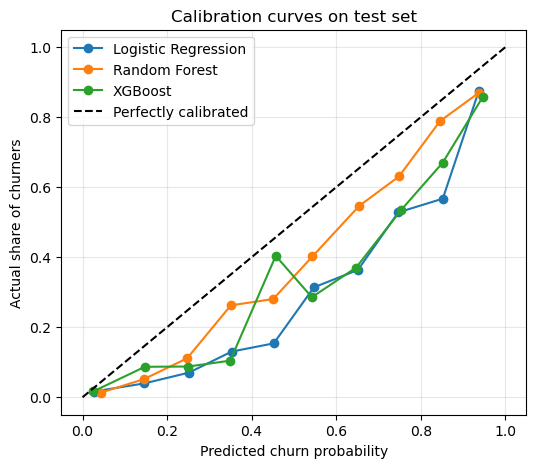

In [55]:
from sklearn.calibration import calibration_curve

lr_true, lr_pred_mean = calibration_curve(y_test, lr_test_proba, n_bins=10)
rf_true, rf_pred_mean = calibration_curve(y_test, rf_test_proba, n_bins=10)
xgb_true, xgb_pred_mean = calibration_curve(y_test, xgb_test_proba, n_bins=10)

plt.figure(figsize=(6, 5))
plt.plot(lr_pred_mean, lr_true, marker="o", label="Logistic Regression")
plt.plot(rf_pred_mean, rf_true, marker="o", label="Random Forest")
plt.plot(xgb_pred_mean, xgb_true, marker="o", label="XGBoost")
plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.xlabel("Predicted churn probability")
plt.ylabel("Actual share of churners")
plt.title("Calibration curves on test set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [56]:
thr_rows = []
for thr in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (xgb_proba >= thr).astype(int)
    thr_rows.append({"Threshold": thr, "Flagged": int(pred.sum()),
                     "Precision": precision_score(y_val, pred),
                     "Recall": recall_score(y_val, pred),
                     "F1": f1_score(y_val, pred)})
pd.DataFrame(thr_rows).set_index("Threshold").round(3)

,Flagged,Precision,Recall,F1
Threshold,,,,
0.2,522,0.496,0.925,0.646
0.3,464,0.543,0.900,0.677
0.4,420,0.571,0.857,0.686
0.5,372,0.602,0.800,0.687
0.6,320,0.650,0.743,0.693
0.7,270,0.707,0.682,0.695
0.8,209,0.761,0.568,0.650


In [57]:
ths = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_val, (xgb_proba >= t).astype(int)) for t in ths]
best_thr = ths[int(np.argmax(f1s))]

best_pred = (xgb_test_proba >= best_thr).astype(int)
print("Best threshold (chosen on validation):", round(best_thr, 2))
print("Test precision:", round(precision_score(y_test, best_pred), 3))
print("Test recall   :", round(recall_score(y_test, best_pred), 3))
print("Test F1       :", round(f1_score(y_test, best_pred), 3))
print(confusion_matrix(y_test, best_pred))

Best threshold (chosen on validation): 0.74
Test precision: 0.744
Test recall   : 0.673
Test F1       : 0.707
[[711  65]
 [ 92 189]]


## Section 4: Error analysis

In [58]:
test_raw = pd.read_csv(PROCESSED_DATA_DIR / "test_raw.csv")
assert len(test_raw) == len(X_test) and (test_raw["Churn"].values == y_test.values).all()   # rows line up

err = test_raw[["Contract", "Tenure_Group", "Internet Type", "Offer", "Age_Band", "Gender",
                "Married", "Has_Dependents", "Number of Referrals", "Monthly Charge",
                "Tenure in Months"]].copy()
err["actual"] = y_test.values
err["proba"] = xgb_test_proba
err["pred"] = xgb_test_pred

err["outcome"] = np.select(
    [(err.actual == 1) & (err.pred == 1), (err.actual == 0) & (err.pred == 1), (err.actual == 1) & (err.pred == 0)],
    ["TP", "FP", "FN"], default="TN")
err["outcome"].value_counts()

outcome
TN    622
TP    235
FP    154
FN     46
Name: count, dtype: int64

In [59]:
for col in ["Contract", "Tenure_Group", "Internet Type", "Offer"]:
    g = err.groupby(col)
    seg = pd.DataFrame({
        "Customers": g.size(),
        "Actual churn rate": g["actual"].mean(),
        "Flagged rate": g["pred"].mean(),
        "Recall": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),
        "Precision": g.apply(lambda d: precision_score(d["actual"], d["pred"], zero_division=0)),
        "Missed churners": g.apply(lambda d: int(((d["actual"] == 1) & (d["pred"] == 0)).sum())),
        "False alarms": g.apply(lambda d: int(((d["actual"] == 0) & (d["pred"] == 1)).sum())),
    }).round(3)
    print(col)
    display(seg)

Contract


C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Recall": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Precision": g.apply(lambda d: precision_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\s

,Customers,Actual churn rate,Flagged rate,Recall,Precision,Missed churners,False alarms
Contract,,,,,,,
Month-to-Month,558,0.439,0.624,0.882,0.621,29,132
One Year,218,0.147,0.179,0.562,0.462,14,21
Two Year,281,0.014,0.007,0.250,0.500,3,1


Tenure_Group


C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Recall": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Precision": g.apply(lambda d: precision_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\s

,Customers,Actual churn rate,Flagged rate,Recall,Precision,Missed churners,False alarms
Tenure_Group,,,,,,,
0-12m,323,0.443,0.647,0.923,0.632,11,77
13-24m,148,0.291,0.439,0.907,0.600,4,26
25-48m,256,0.238,0.277,0.721,0.620,17,27
49+m,330,0.103,0.133,0.588,0.455,14,24


... (4 outputs left out)

C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Recall": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),


Offer


C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Precision": g.apply(lambda d: precision_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3664554391.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Missed churners": g.apply(lambda d: int(((d["actual"] == 1) & (d["pred"] == 0)).sum())),
C:\U

,Customers,Actual churn rate,Flagged rate,Recall,Precision,Missed churners,False alarms
Offer,,,,,,,
No Offer,606,0.264,0.371,0.850,0.604,24,89
Offer A,77,0.078,0.052,0.667,1.000,2,0
Offer B,111,0.135,0.162,0.533,0.444,7,10
Offer C,53,0.245,0.340,0.692,0.500,4,9
Offer D,84,0.274,0.393,0.783,0.545,5,15
Offer E,126,0.508,0.722,0.938,0.659,4,31


In [60]:
print(err.groupby("outcome")[["Tenure in Months", "Monthly Charge", "Number of Referrals"]].mean().round(2))
print()
print(err[err.outcome.isin(["TP", "FN"])].groupby("outcome")["Contract"].value_counts(normalize=True).round(2))

         Tenure in Months  Monthly Charge  Number of Referrals
outcome                                                       
FN                  34.39           61.96                 1.02
FP                  19.97           72.13                 0.31
TN                  40.72           56.06                 2.88
TP                  15.67           74.55                 0.38

outcome  Contract      
FN       Month-to-Month    0.63
         One Year          0.30
         Two Year          0.07
TP       Month-to-Month    0.92
         One Year          0.08
         Two Year          0.00
Name: proportion, dtype: float64


In [61]:
cols = ["Contract", "Tenure in Months", "Monthly Charge", "Internet Type", "Offer", "proba"]
print("Churners the model was most sure would stay (worst misses):")
display(err[err.outcome == "FN"].sort_values("proba").head(5)[cols].round(2))
print("Loyal customers the model was most sure would churn (worst false alarms):")
display(err[err.outcome == "FP"].sort_values("proba", ascending=False).head(5)[cols].round(2))

Churners the model was most sure would stay (worst misses):


,Contract,Tenure in Months,Monthly Charge,Internet Type,Offer,proba
1004,Two Year,59,19.35,No Internet,No Offer,0.01
1006,Month-to-Month,61,19.40,No Internet,No Offer,0.02
346,Two Year,72,92.45,DSL,No Offer,0.03
522,Month-to-Month,48,117.45,Fiber Optic,No Offer,0.03
476,One Year,43,109.55,Fiber Optic,Offer B,0.03


Loyal customers the model was most sure would churn (worst false alarms):


,Contract,Tenure in Months,Monthly Charge,Internet Type,Offer,proba
1015,Month-to-Month,2,91.45,Fiber Optic,No Offer,0.98
557,Month-to-Month,13,59.90,DSL,No Offer,0.96
628,Month-to-Month,4,25.15,DSL,No Offer,0.95
684,Month-to-Month,6,90.75,Fiber Optic,No Offer,0.95
1023,Month-to-Month,1,24.20,Cable,Offer E,0.94


## Section 5: Bias and fairness check

In [62]:
for col in ["Gender", "Age_Band", "Married", "Has_Dependents"]:
    g = err.groupby(col)
    fair = pd.DataFrame({
        "Customers": g.size(),
        "Actual churn rate": g["actual"].mean(),
        "Flagged rate": g["pred"].mean(),
        "TPR": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),
        "FPR": g.apply(lambda d: ((d["pred"] == 1) & (d["actual"] == 0)).sum() / (d["actual"] == 0).sum()),
        "Precision": g.apply(lambda d: precision_score(d["actual"], d["pred"], zero_division=0)),
    })
    print(col)
    display(fair.round(3))
    print("Flagged-rate ratio (lowest / highest):", round(fair["Flagged rate"].min() / fair["Flagged rate"].max(), 2))
    print("TPR gap :", round(fair["TPR"].max() - fair["TPR"].min(), 3))
    print("FPR gap :", round(fair["FPR"].max() - fair["FPR"].min(), 3), "\n")

Gender


C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3507023629.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "TPR": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3507023629.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "FPR": g.apply(lambda d: ((d["pred"] == 1) & (d["actual"] == 0)).sum() / (d["actual"] == 0).sum()),
C:\

,Customers,Actual churn rate,Flagged rate,TPR,FPR,Precision
Gender,,,,,,
Female,539,0.263,0.340,0.817,0.169,0.634
Male,518,0.268,0.398,0.856,0.230,0.578


Flagged-rate ratio (lowest / highest): 0.85
TPR gap : 0.039
FPR gap : 0.061 

Age_Band


C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3507023629.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "TPR": g.apply(lambda d: recall_score(d["actual"], d["pred"], zero_division=0)),
C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3507023629.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "FPR": g.apply(lambda d: ((d["pred"] == 1) & (d["actual"] == 0)).sum() / (d["actual"] == 0).sum()),
C:\

,Customers,Actual churn rate,Flagged rate,TPR,FPR,Precision
Age_Band,,,,,,
30-50,382,0.225,0.343,0.826,0.203,0.542
50+,462,0.320,0.424,0.865,0.217,0.653
<30,213,0.221,0.291,0.766,0.157,0.581


... (4 outputs left out)

Flagged-rate ratio (lowest / highest): 0.46
TPR gap : 0.056
FPR gap : 0.229 

Has_Dependents


C:\Users\saqib\AppData\Local\Temp\ipykernel_22500\3507023629.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Precision": g.apply(lambda d: precision_score(d["actual"], d["pred"], zero_division=0)),


,Customers,Actual churn rate,Flagged rate,TPR,FPR,Precision
Has_Dependents,,,,,,
0,828,0.326,0.452,0.844,0.262,0.610
1,229,0.048,0.066,0.636,0.037,0.467


Flagged-rate ratio (lowest / highest): 0.15
TPR gap : 0.208
FPR gap : 0.225 



In [63]:
meta_test = pd.read_csv(PROCESSED_DATA_DIR / "metadata_test.csv")
err["status"] = meta_test["Customer Status"].values

print(err[err.outcome == "FP"]["status"].value_counts())
print(err.groupby("status")["pred"].mean().round(3))

status
Stayed    110
Joined     44
Name: count, dtype: int64
status
Churned    0.836
Joined     0.564
Stayed     0.158
Name: pred, dtype: float64
